In [1]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import transforms, datasets
# datasets:  이미지 파일과 정답 레이블을 관리하고, 모델 학습에 사용할 수 있는 Dataset 객체를 생성하는 모듈
# transforms: 모델이 학습할 수 있도록 이미지의 크기, 자료형, 차원, 픽셀값 등을 변환하는 모듈입니다. 데이터 증강(Data Augmentation)에도 사용됩니다.
import matplotlib.pyplot as plt
import numpy as np
import os
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [2]:
# function 파일 오류 수정 후 런타임을 재시작하지 않고 수정내용을 반영하는 방법
# import importlib
# import multiclass_functions
# importlib.reload(multiclass_functions)

from multiclass_functions import *

In [3]:
os.makedirs('results', exist_ok=True)

In [4]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()

# 기존 모델을 사용 :False, 새로운 모델 생성 : True
new_model_train=True

model_type = 'CNN'

dataset = 'MNIST'
save_model_path = f'results/{model_type}_{dataset}.pt'

In [5]:
transform = transforms.ToTensor()

train_DS = datasets.MNIST(root='data', train=True, download=True, transform=transform)
test_DS = datasets.MNIST(root='data', train=False, download=True, transform=transform)

train_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size= BATCH_SIZE, shuffle=False)

['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']
{'0 - zero': 0, '1 - one': 1, '2 - two': 2, '3 - three': 3, '4 - four': 4, '5 - five': 5, '6 - six': 6, '7 - seven': 7, '8 - eight': 8, '9 - nine': 9}
1 - one


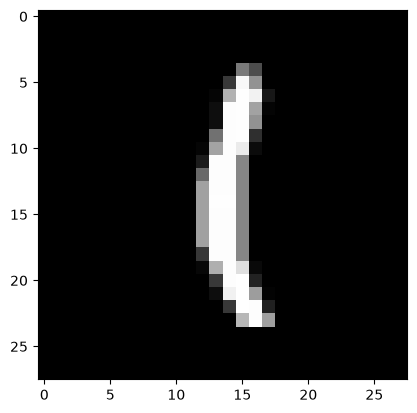

In [6]:
print(test_DS.classes)
print(test_DS.class_to_idx)

x_batch, y_batch = next(iter(train_DL))

plt.imshow(x_batch[0,0], cmap='gray')   # x_batch는 2차원
print(test_DS.classes[y_batch[0]])      # y_batch는 2차원

In [23]:
class CNN(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.conv1 = nn.Sequential(
            nn.Conv2d(1,8,3, padding=1),
            nn.BatchNorm2d(8),
            nn.ReLU()
            )
        self.maxpool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Sequential(
            nn.Conv2d(8,16,3),
            nn.BatchNorm2d(16),
            nn.ReLU()
            )
        self.maxpool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Sequential(
            nn.Conv2d(16,32,3),
            nn.BatchNorm2d(32),
            nn.ReLU()
            )
        self.maxpool3 = nn.MaxPool2d(2)
        self.fc = nn.Linear(32*2*2, 10)

    def forward(self, x, *args, **kwargs):
        x = self.conv1(x)
        x = self.maxpool1(x)
        x = self.conv2(x)
        x = self.maxpool2(x)
        x = self.conv3(x)
        x = self.maxpool3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x


In [24]:
features, labels = next(iter(train_DL))

print(f"입력 데이터 shape: {features.shape}")
print(f"정답 레이블 shape: {labels.shape}")

입력 데이터 shape: torch.Size([32, 1, 28, 28])
정답 레이블 shape: torch.Size([32])


In [25]:
model = globals()[model_type]().to(device)

model.eval()
with torch.no_grad():
    print(model(x_batch.to(device)).shape)

torch.Size([32, 10])


Epoch : 1, train loss : 0.168
--------------------
Epoch : 2, train loss : 0.046
--------------------
Epoch : 3, train loss : 0.036
--------------------
Epoch : 4, train loss : 0.031
--------------------
Epoch : 5, train loss : 0.027
--------------------


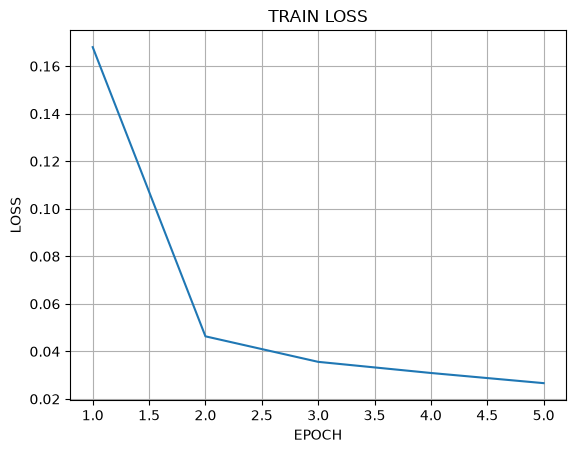

In [26]:
if new_model_train:
    optimizer = optim.Adam(model.parameters(), lr=LR)
    loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

    torch.save(model, save_model_path)

    plt.figure()
    plt.plot(range(1, EPOCH+1), loss_history)
    plt.xlabel('EPOCH')
    plt.ylabel('LOSS')
    plt.title('TRAIN LOSS')
    plt.grid()

In [27]:
load_model = torch.load(save_model_path, map_location= device, weights_only=False)

In [28]:
Test(load_model, test_DL)
print(count_params(load_model))

Test accuracy : 9911 / 10000 (99.1 %)
7290


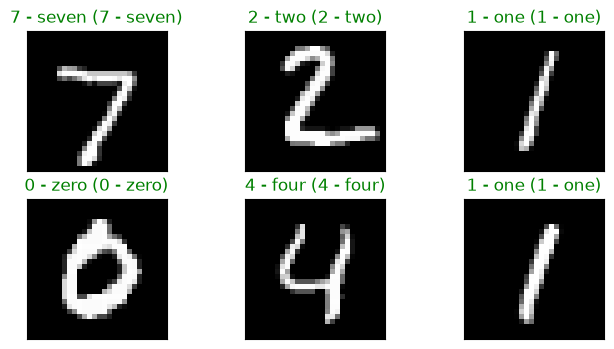

In [29]:
Test_plot(load_model, test_DL)